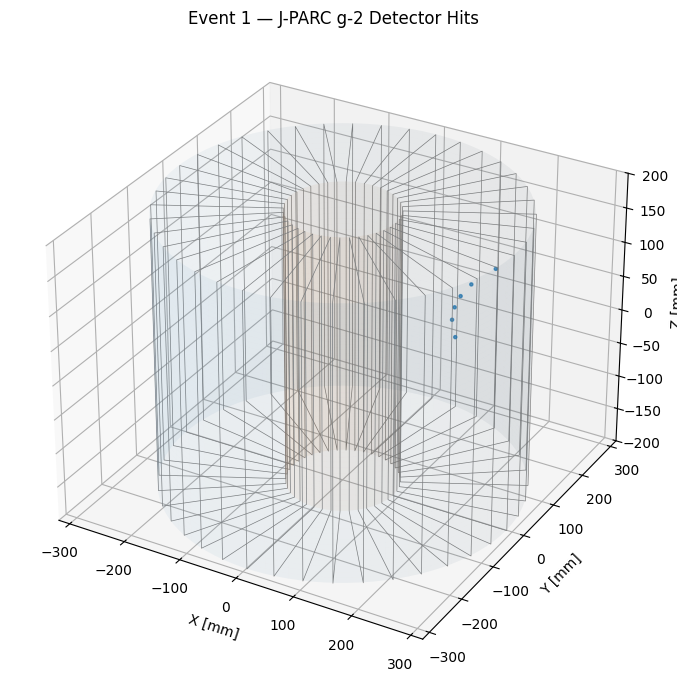

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# -------------------------------
# Detector geometry parameters (FROM YOUR SIM)
# -------------------------------
r_min = 90      # mm
r_max = 290     # mm
z_min = -200    # mm
z_max = 200     # mm
num_vanes = 40
vane_thickness = 0.32  # mm

delta_phi = vane_thickness / r_min  # angular width

# -------------------------------
# Load data
# -------------------------------
df = pd.read_csv("/home/christy/helix_generator/data_hits/detector_hits_50k.csv")

# pick one event
event_id = 1
df_evt = df[df["event"] == event_id]

x = df_evt["x"].values
y = df_evt["y"].values
z = df_evt["z"].values

# -------------------------------
# Geometry function
# -------------------------------
def plot_full_detector_geometry(ax):

    # Cylindrical boundaries
    theta = np.linspace(0, 2*np.pi, 100)
    z_lin = np.linspace(z_min, z_max, 100)
    theta_grid, z_grid = np.meshgrid(theta, z_lin)

    # Outer cylinder
    x_outer = r_max * np.cos(theta_grid)
    y_outer = r_max * np.sin(theta_grid)

    ax.plot_surface(
        x_outer, y_outer, z_grid,
        alpha=0.05, linewidth=0
    )

    # Inner cylinder
    x_inner = r_min * np.cos(theta_grid)
    y_inner = r_min * np.sin(theta_grid)

    ax.plot_surface(
        x_inner, y_inner, z_grid,
        alpha=0.05, linewidth=0
    )

    # ---------------------------
    # Radial vanes (KEY PART)
    # ---------------------------
    for i in range(num_vanes):

        phi = i * 2 * np.pi / num_vanes
        phi1 = phi
        phi2 = phi + delta_phi

        # corners
        x1, y1 = r_min * np.cos(phi1), r_min * np.sin(phi1)
        x2, y2 = r_max * np.cos(phi1), r_max * np.sin(phi1)
        x3, y3 = r_max * np.cos(phi2), r_max * np.sin(phi2)
        x4, y4 = r_min * np.cos(phi2), r_min * np.sin(phi2)

        vertices = [[
            (x1, y1, z_min),
            (x2, y2, z_min),
            (x2, y2, z_max),
            (x1, y1, z_max)
        ]]

        poly = Poly3DCollection(
            vertices,
            facecolors=(0, 0, 0, 0),   # ✅ transparent face (SAFE)
            edgecolors='gray',
            linewidths=0.5
        )
        ax.add_collection3d(poly)

    # Axis limits (detector scale)
    ax.set_xlim(-320, 320)
    ax.set_ylim(-320, 320)
    ax.set_zlim(z_min, z_max)


# -------------------------------
# Create 3D plot
# -------------------------------
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot detector FIRST (background)
plot_full_detector_geometry(ax)

# Plot hits
ax.scatter(x, y, z, s=5, alpha=0.7)

# -------------------------------
# Labels
# -------------------------------
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.set_zlabel("Z [mm]")
ax.set_title(f"Event {event_id} — J-PARC g-2 Detector Hits")

# -------------------------------
# Equal aspect ratio (FIXED)
# -------------------------------
max_range = 320  # match detector size

ax.set_xlim(-max_range, max_range)
ax.set_ylim(-max_range, max_range)
ax.set_zlim(z_min, z_max)

plt.tight_layout()
plt.show()

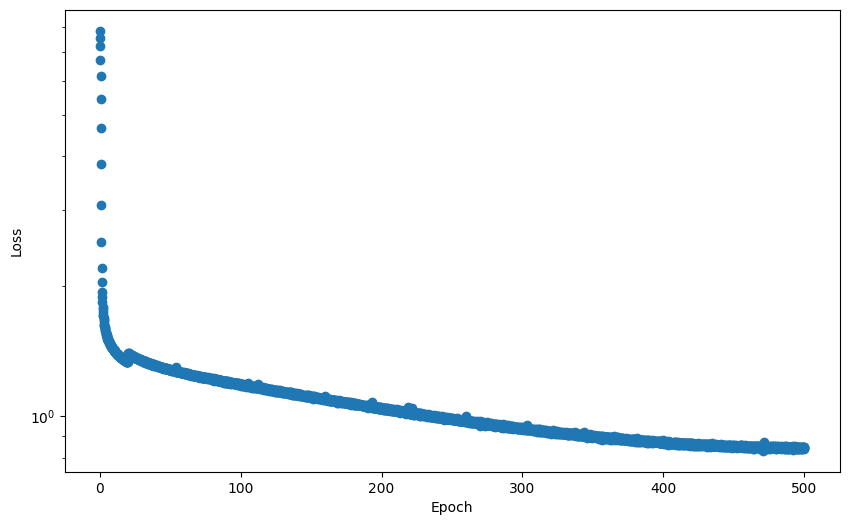

In [11]:
import json
import matplotlib.pyplot as plt

# Load the trainer_state.json file
with open('t5-small-00/checkpoint-75500/trainer_state.json', 'r') as f:
    data = json.load(f)

# Extract epoch and loss from log_history
epochs = [entry['epoch'] for entry in data['log_history'] if 'epoch' in entry and 'loss' in entry]
losses = [entry['loss'] for entry in data['log_history'] if 'epoch' in entry and 'loss' in entry]

# Plot epoch vs loss
plt.figure(figsize=(10, 6))
plt.scatter(epochs, losses, marker='o', colorizer='blue')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.yscale('log')  # Log scale for better visibility of loss values
#plt.xscale('log')  # Linear scale for epochs
#plt.title('Epoch vs Loss')
#plt.grid(True)
plt.show()